importing the dependencies

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn import svm
from sklearn.metrics import accuracy_score

Data Collection

In [3]:
#loading the data from csv file to the pandas dataframe
url="https://raw.githubusercontent.com/ShubhangiJha-dot/Parkinson-s-detection/refs/heads/main/parkinsons.csv"
parkinsons_data = pd.read_csv(url)

EDA

In [4]:
#printing the first rows of the dataframe
parkinsons_data.head()

,name,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),Shimmer:APQ3,Shimmer:APQ5,MDVP:APQ,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
0,phon_R01_S01_1,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,0.426,0.02182,0.03130,0.02971,0.06545,0.02211,21.033,1,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
1,phon_R01_S01_2,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,0.626,0.03134,0.04518,0.04368,0.09403,0.01929,19.085,1,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
2,phon_R01_S01_3,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,0.482,0.02757,0.03858,0.03590,0.08270,0.01309,20.651,1,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
3,phon_R01_S01_4,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.00698,0.01505,0.05492,0.517,0.02924,0.04005,0.03772,0.08771,0.01353,20.644,1,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975
4,phon_R01_S01_5,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.00908,0.01966,0.06425,0.584,0.03490,0.04825,0.04465,0.10470,0.01767,19.649,1,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335


In [5]:
#number of rows and columns in dataframe
parkinsons_data.shape

(195, 24)

In [6]:
#getting more information about the dataset
parkinsons_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 195 entries, 0 to 194
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   name              195 non-null    object 
 1   MDVP:Fo(Hz)       195 non-null    float64
 2   MDVP:Fhi(Hz)      195 non-null    float64
 3   MDVP:Flo(Hz)      195 non-null    float64
 4   MDVP:Jitter(%)    195 non-null    float64
 5   MDVP:Jitter(Abs)  195 non-null    float64
 6   MDVP:RAP          195 non-null    float64
 7   MDVP:PPQ          195 non-null    float64
 8   Jitter:DDP        195 non-null    float64
 9   MDVP:Shimmer      195 non-null    float64
 10  MDVP:Shimmer(dB)  195 non-null    float64
 11  Shimmer:APQ3      195 non-null    float64
 12  Shimmer:APQ5      195 non-null    float64
 13  MDVP:APQ          195 non-null    float64
 14  Shimmer:DDA       195 non-null    float64
 15  NHR               195 non-null    float64
 16  HNR               195 non-null    float64
 1

In [7]:
#checking for missing values in each column
parkinsons_data.isnull().sum()

,0
name,0
MDVP:Fo(Hz),0
MDVP:Fhi(Hz),0
MDVP:Flo(Hz),0
MDVP:Jitter(%),0
MDVP:Jitter(Abs),0
MDVP:RAP,0
MDVP:PPQ,0
Jitter:DDP,0
MDVP:Shimmer,0


In [8]:
#getting some statistical  measures about the data
parkinsons_data.describe()

,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),Shimmer:APQ3,Shimmer:APQ5,MDVP:APQ,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
count,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000
mean,154.228641,197.104918,116.324631,0.006220,0.000044,0.003306,0.003446,0.009920,0.029709,0.282251,0.015664,0.017878,0.024081,0.046993,0.024847,21.885974,0.753846,0.498536,0.718099,-5.684397,0.226510,2.381826,0.206552
std,41.390065,91.491548,43.521413,0.004848,0.000035,0.002968,0.002759,0.008903,0.018857,0.194877,0.010153,0.012024,0.016947,0.030459,0.040418,4.425764,0.431878,0.103942,0.055336,1.090208,0.083406,0.382799,0.090119
min,88.333000,102.145000,65.476000,0.001680,0.000007,0.000680,0.000920,0.002040,0.009540,0.085000,0.004550,0.005700,0.007190,0.013640,0.000650,8.441000,0.000000,0.256570,0.574282,-7.964984,0.006274,1.423287,0.044539
25%,117.572000,134.862500,84.291000,0.003460,0.000020,0.001660,0.001860,0.004985,0.016505,0.148500,0.008245,0.009580,0.013080,0.024735,0.005925,19.198000,1.000000,0.421306,0.674758,-6.450096,0.174351,2.099125,0.137451
50%,148.790000,175.829000,104.315000,0.004940,0.000030,0.002500,0.002690,0.007490,0.022970,0.221000,0.012790,0.013470,0.018260,0.038360,0.011660,22.085000,1.000000,0.495954,0.722254,-5.720868,0.218885,2.361532,0.194052
75%,182.769000,224.205500,140.018500,0.007365,0.000060,0.003835,0.003955,0.011505,0.037885,0.350000,0.020265,0.022380,0.029400,0.060795,0.025640,25.075500,1.000000,0.587562,0.761881,-5.046192,0.279234,2.636456,0.252980
max,260.105000,592.030000,239.170000,0.033160,0.000260,0.021440,0.019580,0.064330,0.119080,1.302000,0.056470,0.079400,0.137780,0.169420,0.314820,33.047000,1.000000,0.685151,0.825288,-2.434031,0.450493,3.671155,0.527367


In [9]:
#distribution of target variable
parkinsons_data['status'].value_counts()

,count
status,
1,147
0,48


0-->healthy person

1-->parkinson's positive

In [10]:
X=parkinsons_data.drop(columns=['name','status'],axis=1)
Y=parkinsons_data['status']

EDA

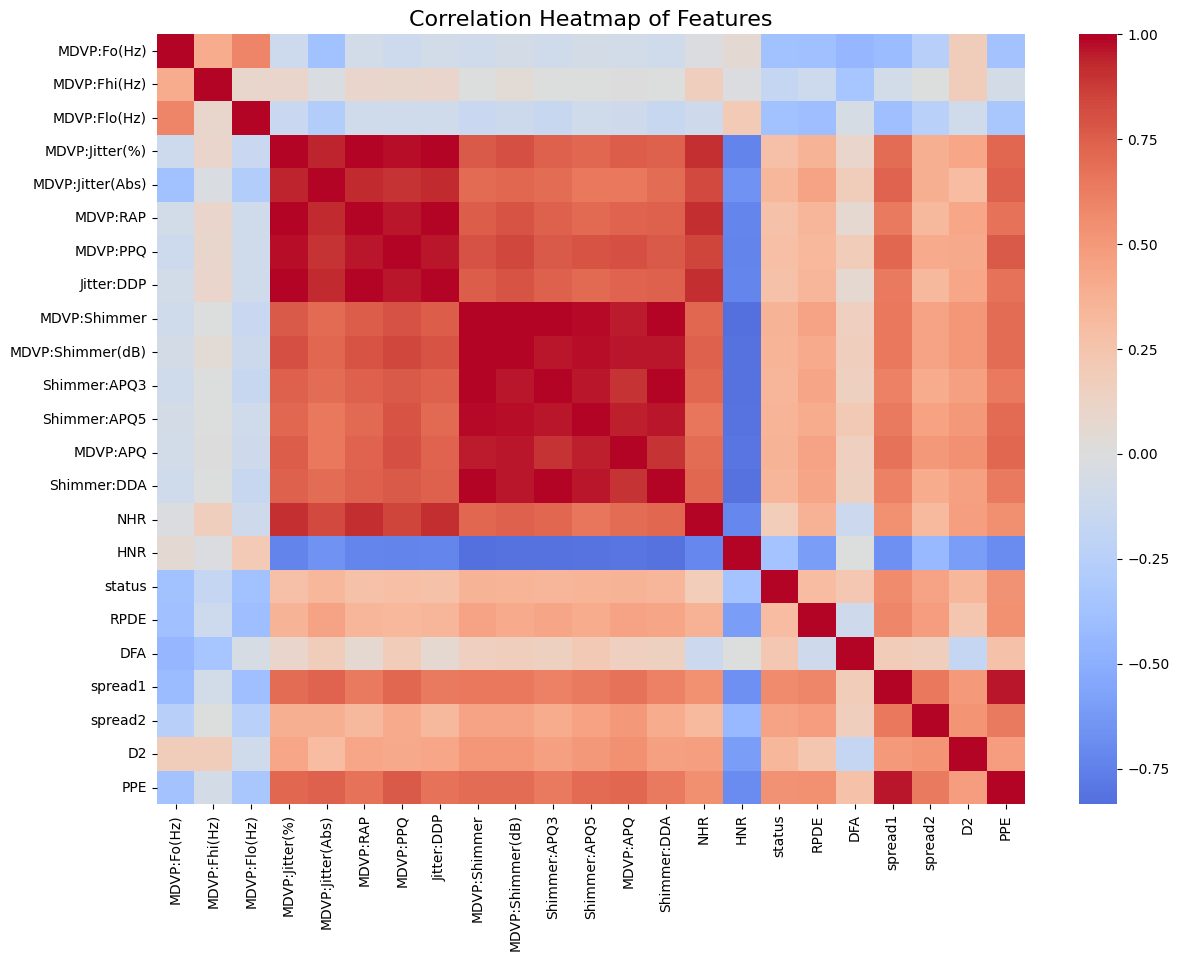

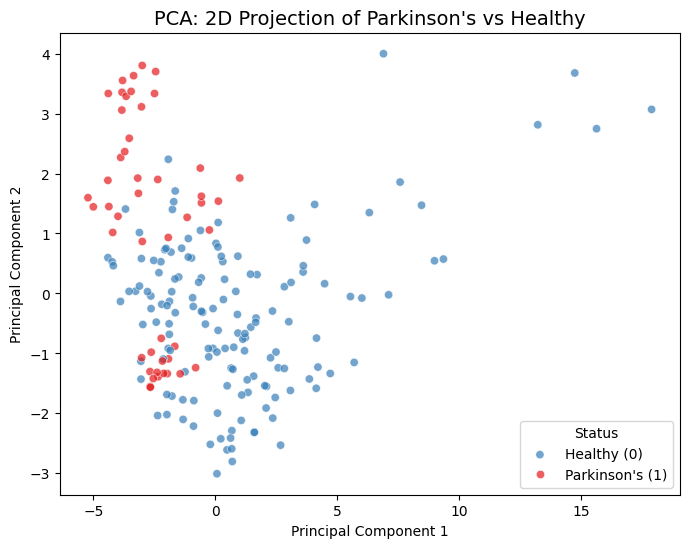

In [11]:


import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, learning_curve, StratifiedKFold
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Load dataset
df = pd.read_csv("https://raw.githubusercontent.com/ShubhangiJha-dot/Parkinson-s-detection/refs/heads/main/parkinsons.csv")

# Split features and labels
X = df.drop(columns=["name", "status"])
y = df["status"]

# Standardize features for PCA
X_scaled = StandardScaler().fit_transform(X)

# -------------------------------------------------------------------
# 1. Correlation Heatmap
plt.figure(figsize=(14,10))
corr = df.drop(columns=["name"]).corr()
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Features", fontsize=16)
plt.show()

# -------------------------------------------------------------------
# 2. PCA Scatter Plot (2D)
pca = PCA(n_components=2)
pca_result = pca.fit_transform(X_scaled)

plt.figure(figsize=(8,6))
sns.scatterplot(x=pca_result[:,0], y=pca_result[:,1], hue=y, palette="Set1", alpha=0.7)
plt.title("PCA: 2D Projection of Parkinson's vs Healthy", fontsize=14)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Status", labels=["Healthy (0)", "Parkinson's (1)"])
plt.show()


data preprocessing

separating the features and target


In [12]:
#grouping  the data based on the target variable
parkinsons_data.groupby('status').mean(numeric_only=True)


,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),Shimmer:APQ3,Shimmer:APQ5,MDVP:APQ,Shimmer:DDA,NHR,HNR,RPDE,DFA,spread1,spread2,D2,PPE
status,,,,,,,,,,,,,,,,,,,,,,
0,181.937771,223.636750,145.207292,0.003866,0.000023,0.001925,0.002056,0.005776,0.017615,0.162958,0.009504,0.010509,0.013305,0.028511,0.011483,24.678750,0.442552,0.695716,-6.759264,0.160292,2.154491,0.123017
1,145.180762,188.441463,106.893558,0.006989,0.000051,0.003757,0.003900,0.011273,0.033658,0.321204,0.017676,0.020285,0.027600,0.053027,0.029211,20.974048,0.516816,0.725408,-5.333420,0.248133,2.456058,0.233828


In [13]:
print (X)

     MDVP:Fo(Hz)  MDVP:Fhi(Hz)  MDVP:Flo(Hz)  ...   spread2        D2       PPE
0        119.992       157.302        74.997  ...  0.266482  2.301442  0.284654
1        122.400       148.650       113.819  ...  0.335590  2.486855  0.368674
2        116.682       131.111       111.555  ...  0.311173  2.342259  0.332634
3        116.676       137.871       111.366  ...  0.334147  2.405554  0.368975
4        116.014       141.781       110.655  ...  0.234513  2.332180  0.410335
..           ...           ...           ...  ...       ...       ...       ...
190      174.188       230.978        94.261  ...  0.121952  2.657476  0.133050
191      209.516       253.017        89.488  ...  0.129303  2.784312  0.168895
192      174.688       240.005        74.287  ...  0.158453  2.679772  0.131728
193      198.764       396.961        74.904  ...  0.207454  2.138608  0.123306
194      214.289       260.277        77.973  ...  0.190667  2.555477  0.148569

[195 rows x 22 columns]


In [14]:
print(Y)

0      1
1      1
2      1
3      1
4      1
      ..
190    0
191    0
192    0
193    0
194    0
Name: status, Length: 195, dtype: int64


Splitting data into Training Data and Test data

In [15]:
X_train, X_test, Y_train, Y_test= train_test_split(X,Y,test_size=0.2,random_state=2)

In [16]:
print(X.shape, X_train.shape, X_test.shape)

(195, 22) (156, 22) (39, 22)


Data Standardization

In [17]:
scaler=StandardScaler()

In [18]:
scaler.fit(X_train)

StandardScaler()

In [19]:
X_train=scaler.transform(X_train)

X_test=scaler.transform(X_test)

In [20]:
print(X_train)

[[ 0.63239631 -0.02731081 -0.87985049 ... -0.97586547 -0.55160318
   0.07769494]
 [-1.05512719 -0.83337041 -0.9284778  ...  0.3981808  -0.61014073
   0.39291782]
 [ 0.02996187 -0.29531068 -1.12211107 ... -0.43937044 -0.62849605
  -0.50948408]
 ...
 [-0.9096785  -0.6637302  -0.160638   ...  1.22001022 -0.47404629
  -0.2159482 ]
 [-0.35977689  0.19731822 -0.79063679 ... -0.17896029 -0.47272835
   0.28181221]
 [ 1.01957066  0.19922317 -0.61914972 ... -0.716232    1.23632066
  -0.05829386]]


Model Training


Support Vector Machine Model

In [21]:
model=svm.SVC(kernel='linear')

In [22]:
#Training the SVM Model with training data
model.fit(X_train, Y_train)

SVC(kernel='linear')

In [23]:
import pickle

# save model
filename = 'parkinson_svm_model.sav'
pickle.dump(model, open(filename, 'wb'))

# save scaler
scaler_filename = 'parkinson_scaler.sav'
pickle.dump(scaler, open(scaler_filename, 'wb'))


In [24]:
model.get_params() #getting its parameters

{'C': 1.0,
 'break_ties': False,
 'cache_size': 200,
 'class_weight': None,
 'coef0': 0.0,
 'decision_function_shape': 'ovr',
 'degree': 3,
 'gamma': 'scale',
 'kernel': 'linear',
 'max_iter': -1,
 'probability': False,
 'random_state': None,
 'shrinking': True,
 'tol': 0.001,
 'verbose': False}

Model Evaluation


Accuracy Score

In [25]:
#Accuracy Score on training data
X_train_prediction=model.predict(X_train)
training_data_accuracy=accuracy_score(Y_train,X_train_prediction)

In [26]:
print('Accuracy Score of Training Data: ', training_data_accuracy)

Accuracy Score of Training Data:  0.8846153846153846


In [27]:
#Accuracy Score on testing data
X_test_prediction=model.predict(X_test)
testing_data_accuracy=accuracy_score(Y_test,X_test_prediction)
print('Accuracy Score of Testing Data: ', testing_data_accuracy)

Accuracy Score of Testing Data:  0.8717948717948718


Model Evaluation/Diagnostics


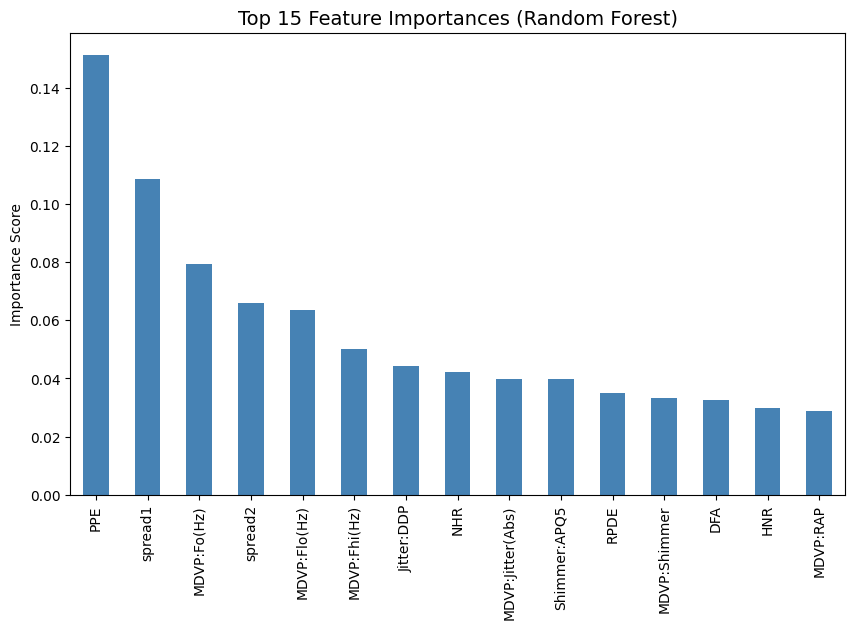

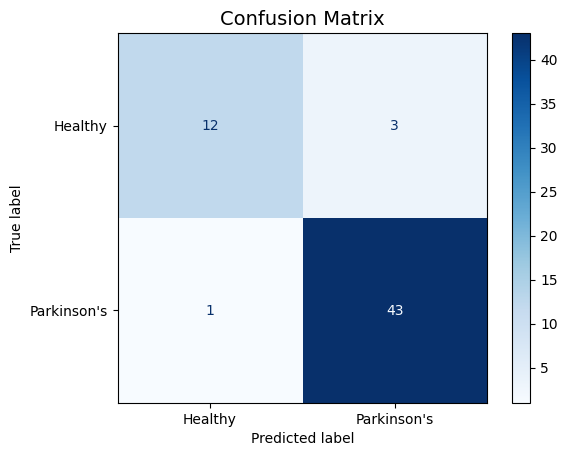

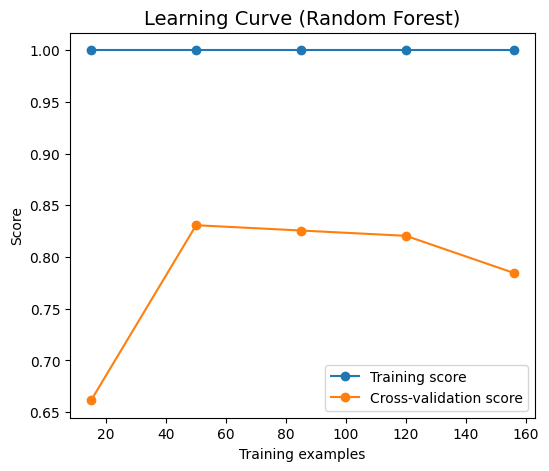

In [28]:
 import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, learning_curve, StratifiedKFold
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Load dataset
df = pd.read_csv("https://raw.githubusercontent.com/ShubhangiJha-dot/Parkinson-s-detection/refs/heads/main/parkinsons.csv")

# Split features and labels
X = df.drop(columns=["name", "status"])
y = df["status"]

# Standardize features for PCA
X_scaled = StandardScaler().fit_transform(X)
#3. Feature Importance (Random Forest)
rf = RandomForestClassifier(random_state=42)
rf.fit(X, y)
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10,6))
importances[:15].plot(kind="bar", color="steelblue")
plt.title("Top 15 Feature Importances (Random Forest)", fontsize=14)
plt.ylabel("Importance Score")
plt.show()

# -------------------------------------------------------------------
# 4. Confusion Matrix
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3,
                                                    random_state=42, stratify=y)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=["Healthy", "Parkinson's"])
disp.plot(cmap="Blues")
plt.title("Confusion Matrix", fontsize=14)
plt.show()

# -------------------------------------------------------------------
# 5. Learning Curve (Random Forest)
train_sizes, train_scores, test_scores = learning_curve(
    rf, X, y, cv=StratifiedKFold(5), n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 5)
)

train_scores_mean = np.mean(train_scores, axis=1)
test_scores_mean = np.mean(test_scores, axis=1)

plt.figure(figsize=(6,5))
plt.plot(train_sizes, train_scores_mean, "o-", label="Training score")
plt.plot(train_sizes, test_scores_mean, "o-", label="Cross-validation score")
plt.title("Learning Curve (Random Forest)", fontsize=14)
plt.xlabel("Training examples")
plt.ylabel("Score")
plt.legend(loc="best")
plt.show()


Building a Predictive System

In [29]:
input_data=(116.68200,131.11100,111.55500,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,0.48200,0.02757,0.03858,0.03590,0.08270,0.01309,20.65100,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634)

#transforming input data into numpy array
input_data_as_numpy_array=np.asarray(input_data)

#reshape the numpy array
input_data_reshaped=input_data_as_numpy_array.reshape(1,-1)

#standardizing data
std_data=scaler.transform(input_data_reshaped)

prediction=model.predict(std_data)
print(prediction)

if(prediction[0]==0):
    print("The person does not have Parkinson's Disease")

else:
  print("The person has Parkinson's Disease")


[1]
The person has Parkinson's Disease


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [30]:
import gradio as gr
import numpy as np

def predict_parkinsons(input_string):
    try:
        values = list(map(float, input_string.split(",")))
        print("Received input length:", len(values))  # DEBUG
        print("Received values:", values)

        if len(values) != X.shape[1]:
            return f"❌ Error: Model expects {X.shape[1]} values, but received {len(values)}."

        input_data = np.array(values).reshape(1, -1)

        # scale
        std_data = scaler.transform(input_data)

        prediction = model.predict(std_data)

        return "🩺 Parkinson's Detected" if prediction[0] == 1 else "✅ Healthy Voice"

    except Exception as e:
        return f"❌ Internal Error: {str(e)}"



# Gradio UI
textbox = gr.Textbox(
    label="Enter 22 feature values (comma-separated)",
    placeholder="e.g. 119.992,157.302,74.997,0.00784,..."
)

iface = gr.Interface(
    fn=predict_parkinsons,
    inputs=textbox,
    outputs="text",
    title="Parkinson's Disease Detection",
    description="Paste all 22 voice features separated by commas.",
    allow_flagging="never"
)

iface.launch()


# input for 1: 116.68200,131.11100,111.55500,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,0.48200,0.02757,0.03858,0.03590,0.08270,0.01309,20.65100,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
#input for 0: 174.68800,240.00500,74.28700,0.01360,0.00008,0.00624,0.00564,0.01873,0.02308,0.25600,0.01268,0.01365,0.01667,0.03804,0.10715,17.88300,0.407567,0.655683,-6.787197,0.158453,2.679772,0.131728


/usr/local/lib/python3.12/dist-packages/gradio/interface.py:415: UserWarning: The `allow_flagging` parameter in `Interface` is deprecated. Use `flagging_mode` instead.
  warnings.warn(


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9a833f4945ed83f064.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
